# Paprastosios pušies projektas
## 2 dalis. Neigiami pavyzdžiai ir dirvožemio savybės iš SoilGrids

Tikslas: sukurti lentelę modeliui. Kiekviena eilutė yra vieta, kurioje:
- **auga pušis** (`pusis = 1`), tai GBIF taškai iš 1 dalies,
- **pušies nėra** (`pusis = 0`), tai atsitiktiniai taškai Lietuvoje, kuriuos sugeneruosime,

o stulpeliuose bus dirvožemio savybės (pH, smėlis, molis, organinė anglis).

**Prieš pradedant:** turi būti 1 dalies failas `pusis_isvalyta.csv` (jį sukūrė pirmas sąsiuvinys) ir veikiantis internetas.
Paleiskite langelius iš eilės (Shift + Enter).

### 1. Bibliotekos

In [31]:
 #Jei kuri nors biblioteka nerasta, atkomentuokite eilutę (pašalinkite #) ir paleiskite vieną kartą:
%pip install rasterio requests

import json
import zipfile
import io
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import rasterio
from rasterio.warp import transform
from matplotlib.path import Path as Kontūras
import matplotlib.pyplot as plt

print("Bibliotekos įkeltos")

Note: you may need to restart the kernel to use updated packages.
Bibliotekos įkeltos


### 2. Pušies taškai (teigiami pavyzdžiai)

In [32]:
rasti = sorted(Path.home().rglob("pusis_isvalyta.csv"), key=lambda f: f.stat().st_mtime, reverse=True)
if not rasti:
    raise FileNotFoundError("Nerastas pusis_isvalyta.csv. Pirmiausia paleiskite 1 dalies sąsiuvinį.")
print("Rastas failas:", rasti[0])

pozityvus = pd.read_csv(rasti[0])
pozityvus = pozityvus[pozityvus["countryCode"] == "LT"].copy()   # tik Lietuva
pozityvus = pozityvus.rename(columns={"decimalLatitude": "lat", "decimalLongitude": "lon"})
pozityvus = pozityvus[["lat", "lon"]]
pozityvus["pusis"] = 1
print("Teigiamų taškų:", len(pozityvus))

Rastas failas: C:\Users\elmek\pusis_isvalyta.csv
Teigiamų taškų: 636


### 3. Lietuvos riba
Neigiamus taškus generuosime tik Lietuvos viduje, todėl reikia šalies ribos. Bandome ją parsisiųsti iš GADM (atvira administracinių ribų duomenų bazė).
Jei nepavyks, naudosime stačiakampį aplink Lietuvą (tada dalis taškų gali patekti į kaimynines šalis, tai reikės paminėti ataskaitoje).

In [33]:
GADM_URL = "https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_LTU_0.json.zip"

kontūrai = []   # Lietuvos ribos poligonai
try:
    atsakymas = requests.get(GADM_URL, timeout=60)
    atsakymas.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(atsakymas.content)) as z:
        vardas = [n for n in z.namelist() if n.endswith(".json")][0]
        geojson = json.loads(z.read(vardas))
    geom = geojson["features"][0]["geometry"]
    poligonai = geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]
    for p in poligonai:
        kontūrai.append(Kontūras(np.array(p[0])))   # išorinis poligono kontūras (lon, lat)
    print("Lietuvos riba parsisiųsta. Dalių:", len(kontūrai))
except Exception as klaida:
    print("Ribos parsisiųsti nepavyko:", klaida)
    print("Naudosime stačiakampį aplink Lietuvą.")

def lietuvoje(lon, lat):
    """Grąžina True/False kiekvienam taškui: ar jis Lietuvos viduje."""
    taskai = np.column_stack([lon, lat])
    if not kontūrai:
        return (lat > 53.9) & (lat < 56.45) & (lon > 20.9) & (lon < 26.85)
    vidus = np.zeros(len(taskai), dtype=bool)
    for k in kontūrai:
        vidus |= k.contains_points(taskai)
    return vidus

Lietuvos riba parsisiųsta. Dalių: 4


### 4. Neigiami pavyzdžiai
Sugeneruojame atsitiktinius taškus Lietuvos viduje, kiek yra ir teigiamų (kad klasės būtų subalansuotos).

Svarbu: tai **pseudo-neigiami** pavyzdžiai. Kai kuriuose iš jų pušis iš tikrųjų gali augti, tik niekas jos neužregistravo. Tai reikia paminėti ataskaitos skyriuje „Ribotumai“.

In [34]:
rng = np.random.default_rng(42)     # fiksuotas skaičius, kad rezultatai kartotųsi
kiek = len(pozityvus)

lat_list, lon_list = [], []
while len(lat_list) < kiek:
    lat = rng.uniform(53.9, 56.45, 5000)
    lon = rng.uniform(20.9, 26.85, 5000)
    ok = lietuvoje(lon, lat)
    lat_list.extend(lat[ok])
    lon_list.extend(lon[ok])

neigiami = pd.DataFrame({"lat": lat_list[:kiek], "lon": lon_list[:kiek]})
neigiami["pusis"] = 0

taskai = pd.concat([pozityvus, neigiami], ignore_index=True)
print(taskai["pusis"].value_counts())
taskai.head()

pusis
1    636
0    636
Name: count, dtype: int64


,lat,lon,pusis
0,54.689197,25.233472,1
1,55.764327,21.085213,1
2,55.508824,25.085028,1
3,54.721744,25.225768,1
4,55.730133,21.115080,1


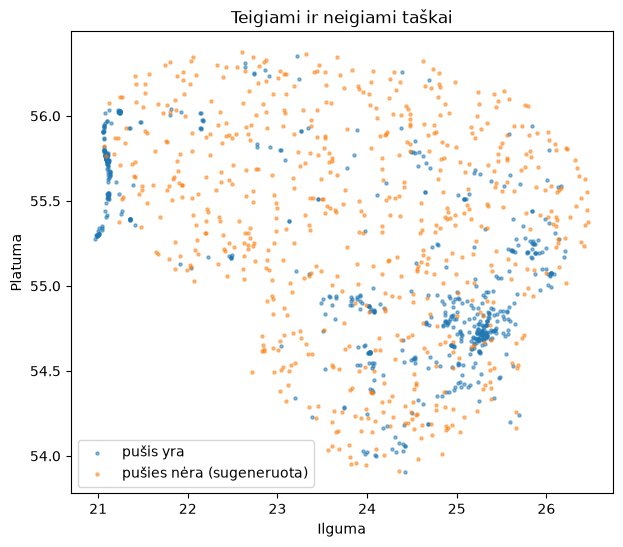

In [35]:
plt.figure(figsize=(7, 6))
for reiksme, pav in [(1, "pušis yra"), (0, "pušies nėra (sugeneruota)")]:
    dalis = taskai[taskai["pusis"] == reiksme]
    plt.scatter(dalis["lon"], dalis["lat"], s=5, alpha=0.5, label=pav)
plt.xlabel("Ilguma"); plt.ylabel("Platuma"); plt.legend()
plt.title("Teigiami ir neigiami taškai")
plt.show()

### 5. Dirvožemio savybių nuskaitymas iš SoilGrids
Naudojame ISRIC failų serverį (WebDAV). Kiekvieną žemėlapį nuskaitome tik tuose taškuose, kurių reikia, todėl visų 5 GB parsisiųsti nereikia.

Savybės: **phh2o** (pH), **sand** (smėlis), **clay** (molis), **soc** (organinė anglis). Gyliai: 0–5, 5–15 ir 15–30 cm. Naudojame vidurkio (`mean`) žemėlapius.

**Pirmiausia išbandome vieną žemėlapį ir keletą taškų.**

In [36]:
BAZE = "https://files.isric.org/soilgrids/latest/data"

def url(savybe, gylis):
    return f"/vsicurl/{BAZE}/{savybe}/{savybe}_{gylis}_mean.vrt"

def nuskaityti(adresas, lon, lat):
    """Nuskaito žemėlapio reikšmes nurodytose vietose (lon, lat). Trūkstama reikšmė = NaN."""
    with rasterio.open(adresas) as src:
        x, y = transform("EPSG:4326", src.crs, list(lon), list(lat))
        reiksmes = np.array([v[0] for v in src.sample(zip(x, y))], dtype="float64")
        if src.nodata is not None:
            reiksmes[reiksmes == src.nodata] = np.nan
    return reiksmes

# Bandymas: pH 0-5 cm, pirmi 5 taškai
bandymas = taskai.head(5)
print(nuskaityti(url("phh2o", "0-5cm"), bandymas["lon"], bandymas["lat"]))

[56. 57. 53. 65. 55.]


**Ką turėtumėte pamatyti:** penkis skaičius apie 40–70 (tai pH, padaugintas iš 10, pvz. 55 reiškia pH 5,5).

- Jei gavote skaičius, einame toliau.
- Jei gavote klaidą arba laukimas užtruko labai ilgai, nukopijuokite klaidos tekstą ir atsiųskite man.

### 6. Visų taškų nuskaitymas
Tai gali užtrukti nuo kelių iki keliasdešimt minučių, nes duomenys skaitomi internetu. Skaičiuoja po vieną žemėlapį ir rašo, kiek jau padaryta.

Jei per ilgai trunka, galite sumažinti gylių sąrašą žemiau iki `["0-5cm", "5-15cm"]`.

In [37]:
import time

SAVYBES = ["phh2o", "sand", "clay", "soc"]
GYLIAI = ["0-5cm", "5-15cm", "15-30cm"]

rezultatas = taskai.copy()
pradzia = time.time()

for savybe in SAVYBES:
    for gylis in GYLIAI:
        stulpelis = f"{savybe}_{gylis}"
        rezultatas[stulpelis] = nuskaityti(url(savybe, gylis), rezultatas["lon"], rezultatas["lat"]) / 10
        print(f"{stulpelis}: baigta (praėjo {time.time() - pradzia:.0f} s)")

print("Viskas nuskaityta")

phh2o_0-5cm: baigta (praėjo 20 s)
phh2o_5-15cm: baigta (praėjo 54 s)
phh2o_15-30cm: baigta (praėjo 83 s)
sand_0-5cm: baigta (praėjo 114 s)
sand_5-15cm: baigta (praėjo 154 s)
sand_15-30cm: baigta (praėjo 190 s)
clay_0-5cm: baigta (praėjo 230 s)
clay_5-15cm: baigta (praėjo 259 s)
clay_15-30cm: baigta (praėjo 296 s)
soc_0-5cm: baigta (praėjo 341 s)
soc_5-15cm: baigta (praėjo 395 s)
soc_15-30cm: baigta (praėjo 419 s)
Viskas nuskaityta


### 7. Patikrinimas ir išsaugojimas
Vienetai: pH yra pH, smėlis ir molis yra %, organinė anglis yra g/kg (reikšmės jau padalintos iš 10).
Tuščios reikšmės (NaN) atsiranda, kai žemėlapyje tame taške nėra duomenų (pvz., vandens telkinys). Tokias eilutes pašaliname.

In [38]:
print("Eilučių prieš valymą:", len(rezultatas))
print("Tuščių reikšmių kiekviename stulpelyje:")
print(rezultatas.isna().sum())

duomenys = rezultatas.dropna().copy()
print("Eilučių po valymo:", len(duomenys))
print(duomenys["pusis"].value_counts())
duomenys.describe().round(1)

Eilučių prieš valymą: 1272
Tuščių reikšmių kiekviename stulpelyje:
lat                0
lon                0
pusis              0
phh2o_0-5cm      117
phh2o_5-15cm     117
phh2o_15-30cm    117
sand_0-5cm       117
sand_5-15cm      117
sand_15-30cm     117
clay_0-5cm       117
clay_5-15cm      117
clay_15-30cm     117
soc_0-5cm        118
soc_5-15cm       118
soc_15-30cm      118
dtype: int64
Eilučių po valymo: 1154
pusis
0    616
1    538
Name: count, dtype: int64


,lat,lon,pusis,phh2o_0-5cm,phh2o_5-15cm,phh2o_15-30cm,sand_0-5cm,sand_5-15cm,sand_15-30cm,clay_0-5cm,clay_5-15cm,clay_15-30cm,soc_0-5cm,soc_5-15cm,soc_15-30cm
count,1154.0,1154.0,1154.0,1154.0,1154.0,1154.0,1154.0,1154.0,1154.0,1154.0,1154.0,1154.0,1154.0,1154.0,1154.0
mean,55.2,23.9,0.5,5.9,6.0,6.0,54.6,55.2,54.3,14.7,14.4,15.8,94.9,52.0,43.2
std,0.6,1.6,0.5,0.6,0.6,0.5,7.5,7.7,8.0,3.3,3.5,4.0,18.0,21.6,16.8
min,53.9,21.0,0.0,4.9,5.0,5.0,23.9,24.0,24.9,5.3,4.7,4.6,43.2,18.9,13.4
25%,54.7,22.7,0.0,5.4,5.6,5.6,50.4,50.9,49.6,12.9,12.3,13.6,83.6,35.8,30.3
50%,55.3,24.2,0.0,5.8,5.9,5.9,54.5,55.3,53.9,15.0,14.6,16.4,94.1,47.8,41.5
75%,55.7,25.2,1.0,6.2,6.4,6.4,59.3,60.2,59.2,16.8,16.6,18.6,106.3,63.6,53.5
max,56.4,26.5,1.0,7.4,7.5,7.5,75.0,75.2,76.4,27.6,27.9,29.3,156.5,139.5,116.7


In [39]:
# Pirmas žvilgsnis: ar pušies vietos skiriasi nuo atsitiktinių?
stulpeliai = ["phh2o_0-5cm", "sand_0-5cm", "clay_0-5cm", "soc_0-5cm"]
duomenys.groupby("pusis")[stulpeliai].mean().round(1)

,phh2o_0-5cm,sand_0-5cm,clay_0-5cm,soc_0-5cm
pusis,,,,
0,6.1,52.5,15.3,92.5
1,5.6,57.0,14.1,97.7


In [40]:
duomenys.to_csv("pusis_su_dirvozemiu.csv", index=False)
print("Išsaugota: pusis_su_dirvozemiu.csv, eilučių:", len(duomenys))

Išsaugota: pusis_su_dirvozemiu.csv, eilučių: 1154


## Ką užrašyti ataskaitai
- **Duomenų šaltiniai:** GBIF (nurodykite DOI ir datą), SoilGrids 2.0 (ISRIC), Lietuvos riba (GADM).
- **Neigiami pavyzdžiai:** sugeneruoti atsitiktinai, tad tai pseudo-neigiami pavyzdžiai (ribotumas).
- **Tikslumas:** GBIF koordinačių netikslumas skiriasi (mediana apie 10 m, didžiausia reikšmė apie 26 km; 17 % įrašų netikslumas nenurodytas), SoilGrids skiriamoji geba yra 250 m ir ji riboja tikslumą labiausiai.
- **Dirvožemio duomenys:** modeliuoti (ne išmatuoti), todėl turi paklaidų.

**Kitas žingsnis (3 dalis):** baseline modelis, RandomForest, metrikos ir SHAP.